# 21. Tensor Products and Tensor Factorizations
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

In [2]:
rng = np.random.default_rng(0); A, B, X = rng.normal(size=(3, 3)), rng.normal(size=(4, 4)), rng.normal(size=(3, 4))
vec = lambda M: M.reshape(-1, order="F")                          # stack columns
print("vec(AXB) = (B^T kron A) vec X:", np.allclose(vec(A @ X @ B), np.kron(B.T, A) @ vec(X)))
lamA, lamB = np.linalg.eigvals(A), np.linalg.eigvals(B)
print("eig(A kron B) = products:", np.allclose(np.sort_complex(np.linalg.eigvals(np.kron(A, B))), np.sort_complex(np.outer(lamA, lamB).ravel())))
print("det(A kron B) = det(A)^4 det(B)^3:", np.isclose(np.linalg.det(np.kron(A, B)), np.linalg.det(A) ** 4 * np.linalg.det(B) ** 3))

vec(AXB) = (B^T kron A) vec X: True
eig(A kron B) = products: True
det(A kron B) = det(A)^4 det(B)^3: True


Eigenvectors of the two-dimensional Laplacian $K\otimes I+I\otimes K$ on a $40\times40$ grid are products $u_j\otimes u_k$ of one-dimensional sine vectors (the vibration modes of a square drum). Shown: six modes with their indices $(j,k)$ and eigenvalues $\lambda_j+\lambda_k$. Modes $(1,2)$ and $(2,1)$ have the same eigenvalue, so any combination of them is also an eigenvector.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


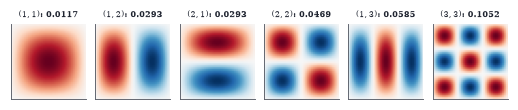

In [3]:
n = 40; K = 2 * np.eye(n) - np.eye(n, k=1) - np.eye(n, k=-1); lam, U = np.linalg.eigh(K)
fig, axs = plt.subplots(1, 6, figsize=(W, 1.2))
for ax, (j, k) in zip(axs, [(1, 1), (1, 2), (2, 1), (2, 2), (1, 3), (3, 3)]):
    mode = np.outer(U[:, j - 1], U[:, k - 1]); ax.imshow(mode, cmap=CMAP, vmin=-np.abs(mode).max(), vmax=np.abs(mode).max())
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"$({j},{k})$: {lam[j - 1] + lam[k - 1]:.4f}", fontsize=5.5)

In [4]:
from itertools import combinations
rng = np.random.default_rng(1); n, k = 5, 2; A = rng.normal(size=(n, n))
idx = list(combinations(range(n), k))
C = np.array([[np.linalg.det(A[np.ix_(I, J)]) for J in idx] for I in idx])       # k-th compound matrix
s = np.linalg.svd(A, compute_uv=False); sC = np.linalg.svd(C, compute_uv=False)
prods = np.sort([s[i] * s[j] for i, j in idx])[::-1]
print("singular values of compound = products of pairs:", np.allclose(sC, prods))
lam = np.linalg.eigvals(A); e2 = sum(lam[i] * lam[j] for i, j in idx)
print("trace of compound = e_2(eigenvalues):", np.isclose(np.trace(C), e2.real))

singular values of compound = products of pairs: True
trace of compound = e_2(eigenvalues): True


Border rank. The rank-3 tensor $T=u\circ u\circ v+u\circ v\circ u+v\circ u\circ u$ is approximated by the rank-2 tensors $T_n$: the error $\lVert T-T_n\rVert$ (blue) tends to $0$ like $1/n$, while the norms of the two rank-one terms (red) grow like $n$. The infimum of the error over rank-2 tensors is $0$, but it is not attained.

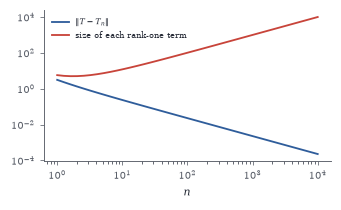

In [5]:
u = np.array([1.0, 0.0]); v = np.array([0.6, 0.8])
outer3 = lambda a, b, c: np.einsum("i,j,k->ijk", a, b, c)
T = outer3(u, u, v) + outer3(u, v, u) + outer3(v, u, u)
ns = np.logspace(0, 4, 40); err, sz = [], []
for n in ns:
    w = u + v / n; Tn = n * outer3(w, w, w) - n * outer3(u, u, u)
    err.append(np.linalg.norm(T - Tn)); sz.append(np.linalg.norm(n * outer3(w, w, w)))
fig, ax = plt.subplots(figsize=(W * 0.65, 1.8))
ax.loglog(ns, err, color=BLUE, label=r"$\|T-T_n\|$"); ax.loglog(ns, sz, color=RED, label="size of each rank-one term")
ax.set_xlabel("$n$"); ax.legend(fontsize=5.5)

CP decomposition by alternating least squares. A $20\times20\times20$ tensor of rank $3$ plus a little noise (relative size $10^{-3}$) is fitted with $R=3$ from random starts; the relative error (one curve per start) typically drops within a few iterations to the noise level, but a bad start can sit on a plateau (a "swamp") for the whole run, as the top curve does here.

Text(0, 0.5, 'relative error')

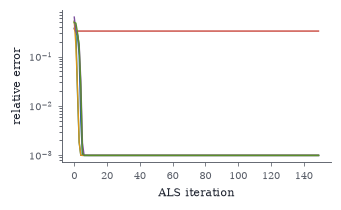

In [6]:
rng = np.random.default_rng(0); I = J = K = 20; R = 3
A0, B0, C0 = rng.normal(size=(I, R)), rng.normal(size=(J, R)), rng.normal(size=(K, R))
T = np.einsum("ir,jr,kr->ijk", A0, B0, C0); T = T + 1e-3 * np.linalg.norm(T) / np.sqrt(T.size) * rng.normal(size=T.shape)
def kr(X, Y): return np.einsum("ir,jr->ijr", X, Y).reshape(-1, X.shape[1])
T1 = T.reshape(I, J * K); T2 = np.moveaxis(T, 1, 0).reshape(J, I * K); T3 = np.moveaxis(T, 2, 0).reshape(K, I * J)
fig, ax = plt.subplots(figsize=(W * 0.65, 1.8))
for trial in range(6):
    A, B, C = rng.normal(size=(I, R)), rng.normal(size=(J, R)), rng.normal(size=(K, R)); errs = []
    for it in range(150):
        A = T1 @ kr(B, C) @ np.linalg.pinv((B.T @ B) * (C.T @ C))
        B = T2 @ kr(A, C) @ np.linalg.pinv((A.T @ A) * (C.T @ C))
        C = T3 @ kr(A, B) @ np.linalg.pinv((A.T @ A) * (B.T @ B))
        errs.append(np.linalg.norm(T - np.einsum("ir,jr,kr->ijk", A, B, C)) / np.linalg.norm(T))
    ax.semilogy(errs, lw=0.9)
ax.set_xlabel("ALS iteration"); ax.set_ylabel("relative error")

Parts from nonnegative data. Each $8\times8$ image (top row, examples) is a random sum of horizontal and vertical bars. Rank-16 NMF (middle row) recovers individual bars as its factors, because nonnegativity forbids cancellation; the leading singular vectors of the same data (bottom row) are signed mixtures of many bars.

Text(0, 0.5, 'SVD')

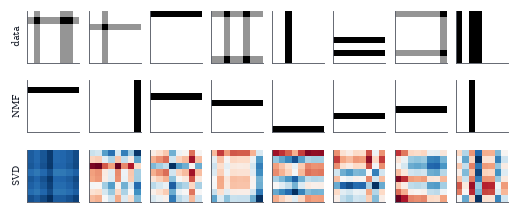

In [7]:
rng = np.random.default_rng(0); n = 8; bars = []
for i in range(n):
    h = np.zeros((n, n)); h[i, :] = 1; bars.append(h.ravel()); v = np.zeros((n, n)); v[:, i] = 1; bars.append(v.ravel())
bars = np.array(bars); Ad = np.array([bars[rng.random(2 * n) < 0.15].sum(0) for _ in range(800)]).T
Wf, Hf = rng.random((64, 16)) + 0.1, rng.random((16, 800)) + 0.1
for it in range(800):
    Hf *= (Wf.T @ Ad) / (Wf.T @ Wf @ Hf + 1e-9); Wf *= (Ad @ Hf.T) / (Wf @ Hf @ Hf.T + 1e-9)
Us = np.linalg.svd(Ad, full_matrices=False)[0]
fig, axs = plt.subplots(3, 8, figsize=(W, 1.9))
for c in range(8):
    axs[0, c].imshow(Ad[:, c].reshape(n, n), cmap="Greys"); axs[1, c].imshow(Wf[:, c].reshape(n, n), cmap="Greys")
    m = Us[:, c].reshape(n, n); axs[2, c].imshow(m, cmap=CMAP, vmin=-np.abs(m).max(), vmax=np.abs(m).max())
for ax in axs.flat: ax.set_xticks([]); ax.set_yticks([])
axs[0, 0].set_ylabel("data", fontsize=6); axs[1, 0].set_ylabel("NMF", fontsize=6); axs[2, 0].set_ylabel("SVD", fontsize=6)

In [8]:
def strassen2(A, B):
    """Multiply 2x2 (block) matrices with 7 products instead of 8."""
    a, b, c, d = A[0, 0], A[0, 1], A[1, 0], A[1, 1]; e, f, g, h = B[0, 0], B[0, 1], B[1, 0], B[1, 1]
    m1 = (a + d) * (e + h); m2 = (c + d) * e; m3 = a * (f - h); m4 = d * (g - e); m5 = (a + b) * h; m6 = (c - a) * (e + f); m7 = (b - d) * (g + h)
    return np.array([[m1 + m4 - m5 + m7, m3 + m5], [m2 + m4, m1 - m2 + m3 + m6]])
rng = np.random.default_rng(0); A, B = rng.normal(size=(2, 2)), rng.normal(size=(2, 2))
print("Strassen's 7 products reproduce AB:", np.allclose(strassen2(A, B), A @ B))

Strassen's 7 products reproduce AB: True
